# Digital Image Processing Lab – Task 04
## Geometric Transformations with Custom Inputs

**Student Name:** Maryam Shaheen 
**Complete Roll Number:** 2024_SE_30
**University:** The University of Azad Jammu and Kashmir  
**Department:** Software Engineering  

**Helper source file:** `lab04_helpers.py` (must be kept in the same folder as this notebook).

## 1. Import libraries, validate and display original image

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import math
print("libraries impotrted successfully")


libraries impotrted successfully


# validate and display original image

Width: 1536 pixels
Height: 1024 pixels
BGR array shape: (1024, 1536, 3)
RGB array shape: (1024, 1536, 3)


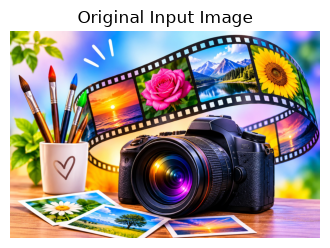

In [2]:
INPUT_PATH = Path("input_image.png")
OUTPUT_DIR = Path("transformed_images")
OUTPUT_DIR.mkdir(exist_ok=True)
MAX_OUTPUT_PIXELS = 40_000_000

if not INPUT_PATH.is_file():
    raise FileNotFoundError(f"Image file does not exist: {INPUT_PATH.resolve()}")
original = cv2.imread(str(INPUT_PATH), cv2.IMREAD_COLOR)
if original is None:
    raise ValueError("File exists but could not be decoded as an image.")
height, width = original.shape[:2]
if width <= 0 or height <= 0:
    raise ValueError("Image dimensions must be nonzero.")
original_rgb = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
print("Width:", width, "pixels")
print("Height:", height, "pixels")
print("BGR array shape:", original.shape)
print("RGB array shape:", original_rgb.shape)
plt.figure(figsize=(4,4)); plt.imshow(original_rgb); plt.title("Original Input Image"); plt.axis("off"); plt.show()

## 2. Reusable transform() function and validation

The reusable functions `transform()`, `finite_number()`, and `check_output_size()` are stored in the separate Python source file `lab04_helpers.py`. The notebook imports them in the next cell. Keep the helper file beside this notebook so the import works.

In [3]:
# The reusable transformation and validation functions are stored in lab04_helpers.py.
# Keep lab04_helpers.py in the same folder as this notebook.
from lab04_helpers import transform, finite_number, check_output_size

print('Helper functions imported successfully from lab04_helpers.py.')

Helper functions imported successfully from lab04_helpers.py.


## 3. Display and save helper

In [4]:
def show_and_save(title, result, filename):
    path=OUTPUT_DIR/filename
    if not cv2.imwrite(str(path),result): raise IOError(f"Could not save {path}")
    display=cv2.cvtColor(result,cv2.COLOR_BGR2RGB) if result.ndim==3 else result
    h,w=result.shape[:2]
    plt.figure(figsize=(4,4)); plt.imshow(display,cmap="gray" if result.ndim==2 else None)
    plt.title(f"{title} | Output dimensions: {w} × {h}"); plt.axis("off"); plt.show()
    print("Saved:",path,"| Shape:",result.shape)


## 4. Scaling – enlargement and reduction

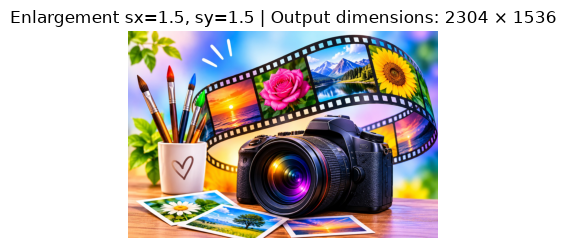

Saved: transformed_images\scaled_enlarged.png | Shape: (1536, 2304, 3)


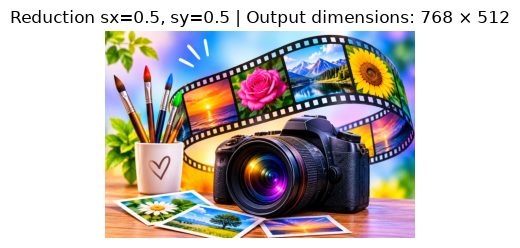

Saved: transformed_images\scaled_reduced.png | Shape: (512, 768, 3)


In [5]:
enlarged=transform(original.copy(),"scale",sx=1.5,sy=1.5,interpolation="bicubic")
reduced=transform(original.copy(),"scale",sx=0.5,sy=0.5,interpolation="bilinear")
show_and_save("Enlargement sx=1.5, sy=1.5",enlarged,"scaled_enlarged.png")
show_and_save("Reduction sx=0.5, sy=0.5",reduced,"scaled_reduced.png")


### Non-proportional scaling (aspect-ratio change)
Different horizontal and vertical factors demonstrate stretching/compression.

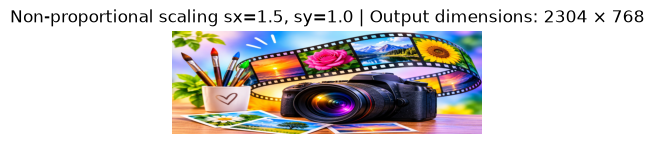

Saved: transformed_images\scaled_non_proportional.png | Shape: (768, 2304, 3)
Original dimensions: (1536, 1024) | New dimensions: (2304, 768)


In [6]:
non_proportional=transform(original.copy(),"scale",sx=1.5,sy=0.75,interpolation="bilinear")
show_and_save("Non-proportional scaling sx=1.5, sy=1.0",non_proportional,"scaled_non_proportional.png")
print("Original dimensions:", (width,height), "| New dimensions:", (non_proportional.shape[1],non_proportional.shape[0]))


## 5. Cropping

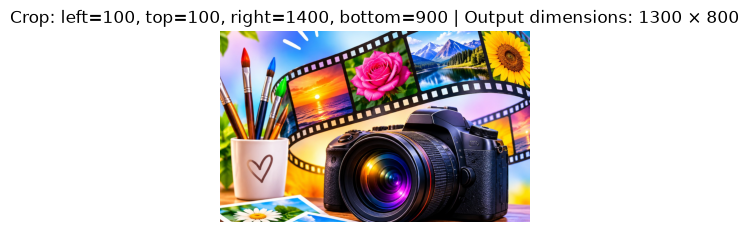

Saved: transformed_images\cropped.png | Shape: (800, 1300, 3)


In [7]:
cropped=transform(original.copy(),"crop",left=100,top=100,right=1400,bottom=900)
show_and_save("Crop: left=100, top=100, right=1400, bottom=900",cropped,"cropped.png")


## 6. Flipping – all three directions

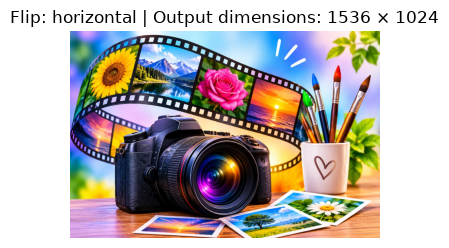

Saved: transformed_images\flip_horizontal.png | Shape: (1024, 1536, 3)


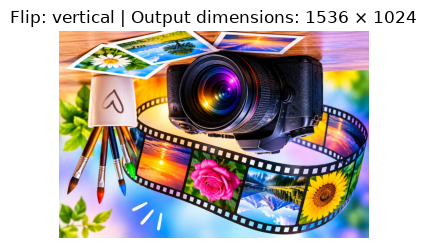

Saved: transformed_images\flip_vertical.png | Shape: (1024, 1536, 3)


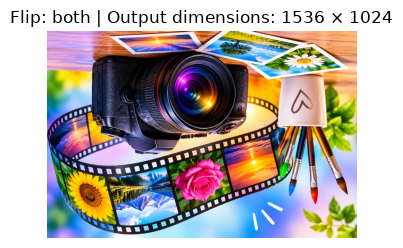

Saved: transformed_images\flip_both.png | Shape: (1024, 1536, 3)


In [8]:
for direction in ["horizontal","vertical","both"]:
    result=transform(original.copy(),"flip",direction=direction)
    show_and_save("Flip: "+direction,result,"flip_"+direction+".png")


## 7. Translation – opposite directions and zero offset

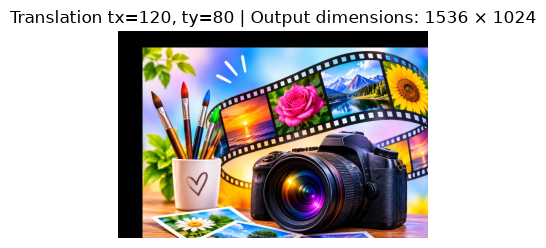

Saved: transformed_images\translated_right_down.png | Shape: (1024, 1536, 3)


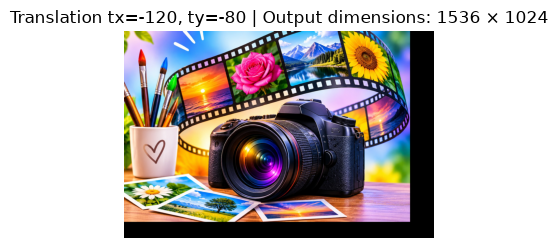

Saved: transformed_images\translated_left_up.png | Shape: (1024, 1536, 3)


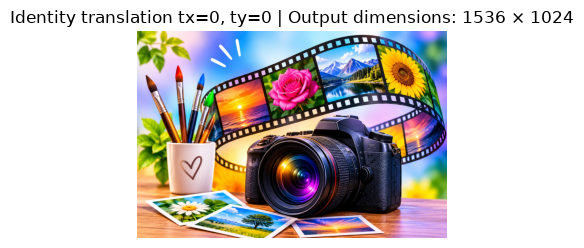

Saved: transformed_images\translated_zero.png | Shape: (1024, 1536, 3)


In [9]:
right_down=transform(original.copy(),"translate",tx=120,ty=80)
left_up=transform(original.copy(),"translate",tx=-120,ty=-80)
zero_translation=transform(original.copy(),"translate",tx=0,ty=0)
show_and_save("Translation tx=120, ty=80",right_down,"translated_right_down.png")
show_and_save("Translation tx=-120, ty=-80",left_up,"translated_left_up.png")
show_and_save("Identity translation tx=0, ty=0",zero_translation,"translated_zero.png")


## 8. Rotation – positive, negative and zero angles

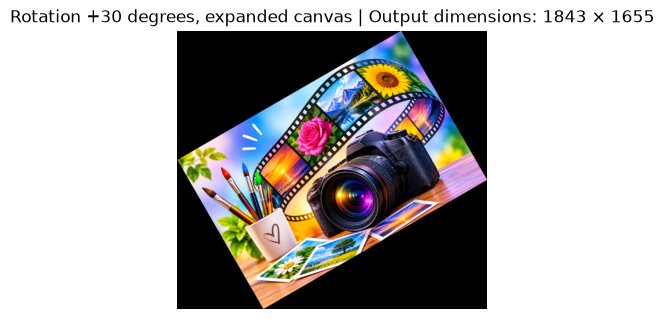

Saved: transformed_images\rotated_positive.png | Shape: (1655, 1843, 3)


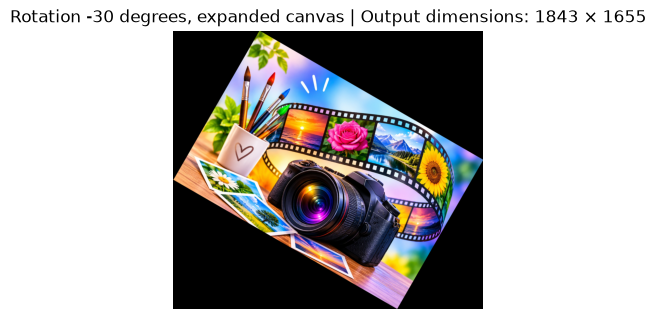

Saved: transformed_images\rotated_negative.png | Shape: (1655, 1843, 3)


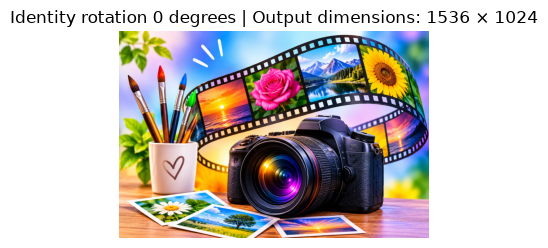

Saved: transformed_images\rotated_zero.png | Shape: (1024, 1536, 3)


In [10]:
positive=transform(original.copy(),"rotate",angle=30,expand=True)
negative=transform(original.copy(),"rotate",angle=-30,expand=True)
zero=transform(original.copy(),"rotate",angle=0,expand=False)
show_and_save("Rotation +30 degrees, expanded canvas",positive,"rotated_positive.png")
show_and_save("Rotation -30 degrees, expanded canvas",negative,"rotated_negative.png")
show_and_save("Identity rotation 0 degrees",zero,"rotated_zero.png")


## 9. Interpolation comparison on the same enlarged image patch

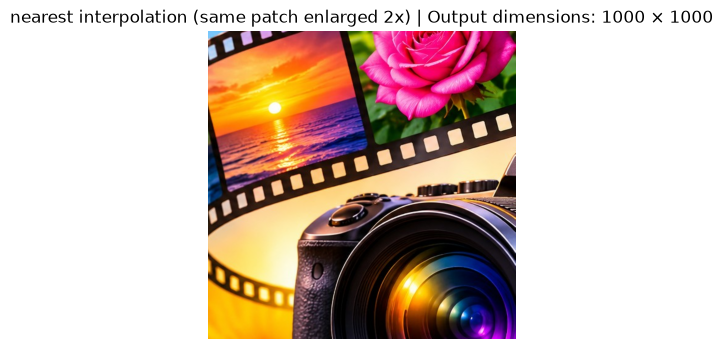

Saved: transformed_images\interpolation_nearest.png | Shape: (1000, 1000, 3)


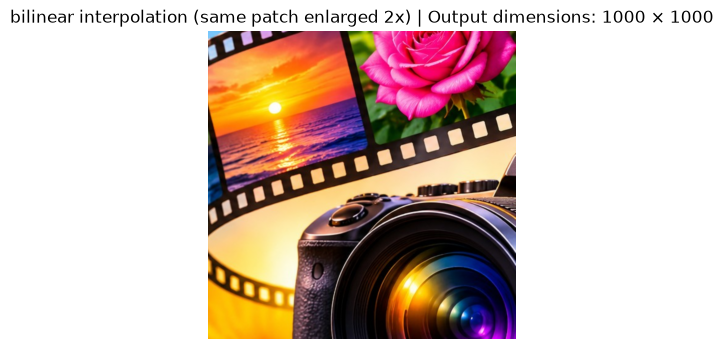

Saved: transformed_images\interpolation_bilinear.png | Shape: (1000, 1000, 3)


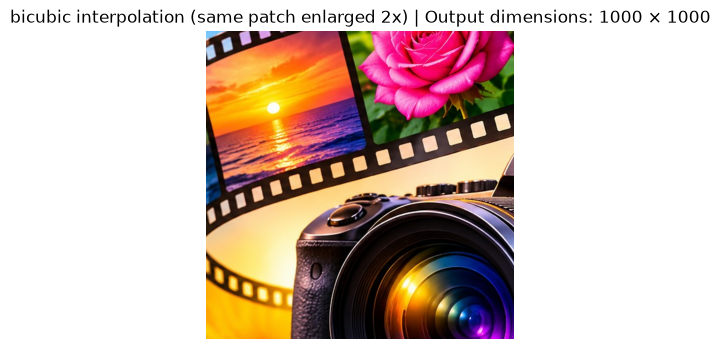

Saved: transformed_images\interpolation_bicubic.png | Shape: (1000, 1000, 3)


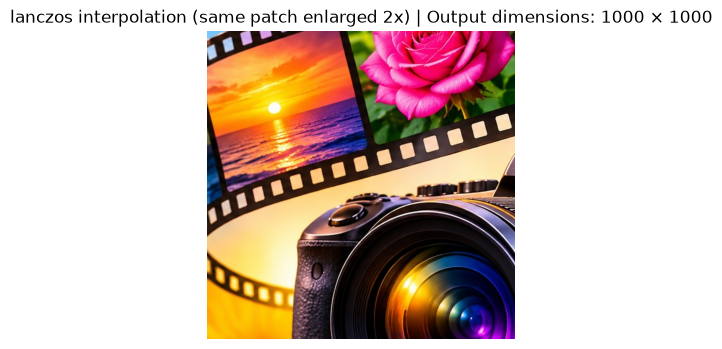

Saved: transformed_images\interpolation_lanczos.png | Shape: (1000, 1000, 3)


In [11]:
patch=original[250:750,400:900].copy()
if patch.size==0: raise ValueError("Selected interpolation patch is empty.")
methods={"nearest":cv2.INTER_NEAREST,"bilinear":cv2.INTER_LINEAR,"bicubic":cv2.INTER_CUBIC,"lanczos":cv2.INTER_LANCZOS4}
for name,method in methods.items():
    enlarged_patch=cv2.resize(patch,(1000,1000),interpolation=method)
    show_and_save(name+" interpolation (same patch enlarged 2x)",enlarged_patch,"interpolation_"+name+".png")


## 10. Invalid-input demonstrations

In [12]:
tests=[
 ("Scaling",lambda:transform(original,"scale",sx=0,sy=1,interpolation="bilinear")),
 ("Cropping",lambda:transform(original,"crop",left=200,top=100,right=100,bottom=500)),
 ("Flipping",lambda:transform(original,"flip",direction="diagonal")),
 ("Translation",lambda:transform(original,"translate",tx=float("nan"),ty=0)),
 ("Rotation",lambda:transform(original,"rotate",angle="not-a-number",expand=True))]
for label,test in tests:
    try: test(); print(label,"FAIL: invalid input accepted")
    except (ValueError,TypeError) as error: print(label,"PASS: rejected:",error)


Scaling PASS: rejected: Scale factors must be greater than zero.
Cropping PASS: rejected: Require 0 <= left < right <= 1536 and 0 <= top < bottom <= 1024.
Flipping PASS: rejected: Direction must be horizontal, vertical or both.
Translation PASS: rejected: tx must be finite (not NaN or infinity).
Rotation PASS: rejected: angle must be numeric.


## 11. Identity checks – expected and actual behaviour

In [13]:
checks=[
 ("Scale factors 1 and 1",original.copy(),transform(original.copy(),"scale",sx=1,sy=1,interpolation="bilinear")),
 ("Translation offsets 0 and 0",original.copy(),transform(original.copy(),"translate",tx=0,ty=0)),
 ("Rotation angle 0 degrees",original.copy(),transform(original.copy(),"rotate",angle=0,expand=False))]
print("| Identity test | Expected behaviour | Actual behaviour | Status |")
print("|---|---|---|---|")
for label,expected,actual in checks:
    passed=expected.shape==actual.shape and np.array_equal(expected,actual)
    actual_text="Image unchanged; dimensions "+str(actual.shape[1])+" x "+str(actual.shape[0]) if passed else "Image differs"
    print("|",label,"| Unchanged image |",actual_text,"|",("PASS" if passed else "FAIL"),"|")


| Identity test | Expected behaviour | Actual behaviour | Status |
|---|---|---|---|
| Scale factors 1 and 1 | Unchanged image | Image unchanged; dimensions 1536 x 1024 | PASS |
| Translation offsets 0 and 0 | Unchanged image | Image unchanged; dimensions 1536 x 1024 | PASS |
| Rotation angle 0 degrees | Unchanged image | Image unchanged; dimensions 1536 x 1024 | PASS |


## 12. User-selected operation with custom prompts

Choose scale, crop, flip, translate or rotate (or q to quit):  scale
Horizontal scale factor sx:  5
Vertical scale factor sy:  5
Interpolation (nearest/bilinear/bicubic/lanczos):  bilinear


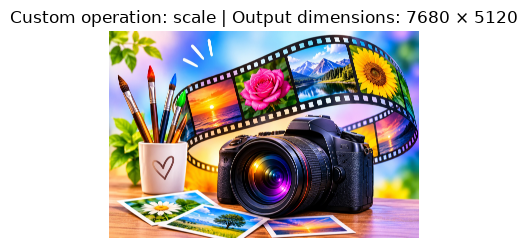

Saved: transformed_images\custom_scale.png | Shape: (5120, 7680, 3)


Choose scale, crop, flip, translate or rotate (or q to quit):  crop
Left:  


Input error: invalid literal for int() with base 10: '' Please enter the values again.


Choose scale, crop, flip, translate or rotate (or q to quit):  q


Custom operation input finished.


In [14]:
def run_custom_operation():
    """Ask for an operation"""
    while True:
        operation=input("Choose scale, crop, flip, translate or rotate (or q to quit): ").strip().lower()
        if operation in ("q","quit","exit"):
            print("Custom operation input finished.")
            break
        try:
            if operation=="scale":
                sx_text=input("Horizontal scale factor sx: "); sy_text=input("Vertical scale factor sy: ")
                method=input("Interpolation (nearest/bilinear/bicubic/lanczos): ").strip().lower()
                result=transform(original.copy(),operation,sx=float(sx_text),sy=float(sy_text),interpolation=method)
            elif operation=="crop":
                left=int(input("Left: ")); top=int(input("Top: ")); right=int(input("Right (exclusive): ")); bottom=int(input("Bottom (exclusive): "))
                result=transform(original.copy(),operation,left=left,top=top,right=right,bottom=bottom)
            elif operation=="flip":
                direction=input("Direction (horizontal/vertical/both): ").strip().lower()
                result=transform(original.copy(),operation,direction=direction)
            elif operation=="translate":
                tx=float(input("Horizontal offset tx: ")); ty=float(input("Vertical offset ty: "))
                result=transform(original.copy(),operation,tx=tx,ty=ty)
            elif operation=="rotate":
                angle=float(input("Angle in degrees: ")); choice=input("Expand canvas? (yes/no): ").strip().lower()
                if choice not in ("yes","no"): raise ValueError("Enter yes or no for canvas expansion.")
                result=transform(original.copy(),operation,angle=angle,expand=(choice=="yes"))
            else:
                raise ValueError("Unknown operation. Choose one of the five supported operations.")
            show_and_save("Custom operation: "+operation,result,"custom_"+operation+".png")
        except (ValueError,TypeError,OverflowError) as error:
            print("Input error:",error,"Please enter the values again.")

# Run this cell when you want to enter your own custom operation.
# The loop lets you correct invalid input or enter q to finish.
run_custom_operation()


## 13. Brief explanations and observations

- **Image coordinates versus array indexing:** image coordinates are (x, y), where x is horizontal and y is vertical. NumPy uses `image[y, x]` because rows come before columns.
- **Aspect-ratio distortion:** different horizontal and vertical scale factors change the width-to-height ratio and stretch or compress objects. Equal factors preserve the ratio.
- **Rotation canvas expansion:** expansion enlarges the output canvas to contain the rotated image. Without expansion, the original canvas is retained and parts may be clipped.
- **Translation clipping:** translation keeps the original canvas size. Pixels shifted outside it are clipped; exposed areas are filled with black.
- **Positive-angle direction:** OpenCV's `getRotationMatrix2D` treats positive angles as counter-clockwise.
- **Interpolation:** nearest-neighbour is more blocky; bilinear is smoother; bicubic generally preserves detail more smoothly; Lanczos often produces sharp enlarged results and may show slight ringing near strong edges.


## 14. Final verification

In [15]:
source_again=cv2.imread(str(INPUT_PATH),cv2.IMREAD_COLOR)
assert np.array_equal(original,source_again),"Original image changed unexpectedly."
print("PASS: Original input image remains unchanged.")
print("Saved results folder:",OUTPUT_DIR.resolve())


PASS: Original input image remains unchanged.
Saved results folder: C:\Users\HP\Desktop\2024-SE-30_Lab04\transformed_images
